# Resample and Bootstrap

# 0. Setup

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

seed = 507

# 1. Experiment

In [21]:
processed_path = '../data/processed/processed.parquet'

df = pd.read_parquet(processed_path)

In [22]:
# Sampling
def firm_gaps(df, k):
    s = df.groupby("firm_id").filter(
        lambda g: (g["former"] == 1).sum() >= k
        and (g["former"] == 0).sum() >= k
    )
    t = s.pivot_table(
        index="firm_id",
        columns="former",
        values="rating",
        aggfunc='mean'
    )
    return t[1] - t[0]

# Bootstrapping
def bootstrap_ci(gaps, seed, n=2000):
    rng = np.random.default_rng(seed)
    x = gaps.to_numpy()
    means = [rng.choice(x, size=len(x)).mean() for _ in range(n)]
    return np.percentile(means, [2.5, 97.5])

In [23]:
rows = []
for k in [5, 10, 20, 50]:
    g = firm_gaps(df, k)
    lo, hi = bootstrap_ci(g, seed)
    rows.append({"k": k, "firms": len(g), "mean": g.mean(), "lower": lo, "upper": hi})

pd.DataFrame(rows)

,k,firms,mean,lower,upper
0,5,10979,-0.619827,-0.630506,-0.609244
1,10,8539,-0.593747,-0.604326,-0.583498
2,20,6495,-0.560594,-0.570578,-0.550459
3,50,4195,-0.512538,-0.522534,-0.502157


# 2. Result

In [24]:
# Get each gap
with open("../data/processed/rq1/rq1_summary.json") as f:
    summary = json.load(f)

overall_gap = summary["overall_gap"]

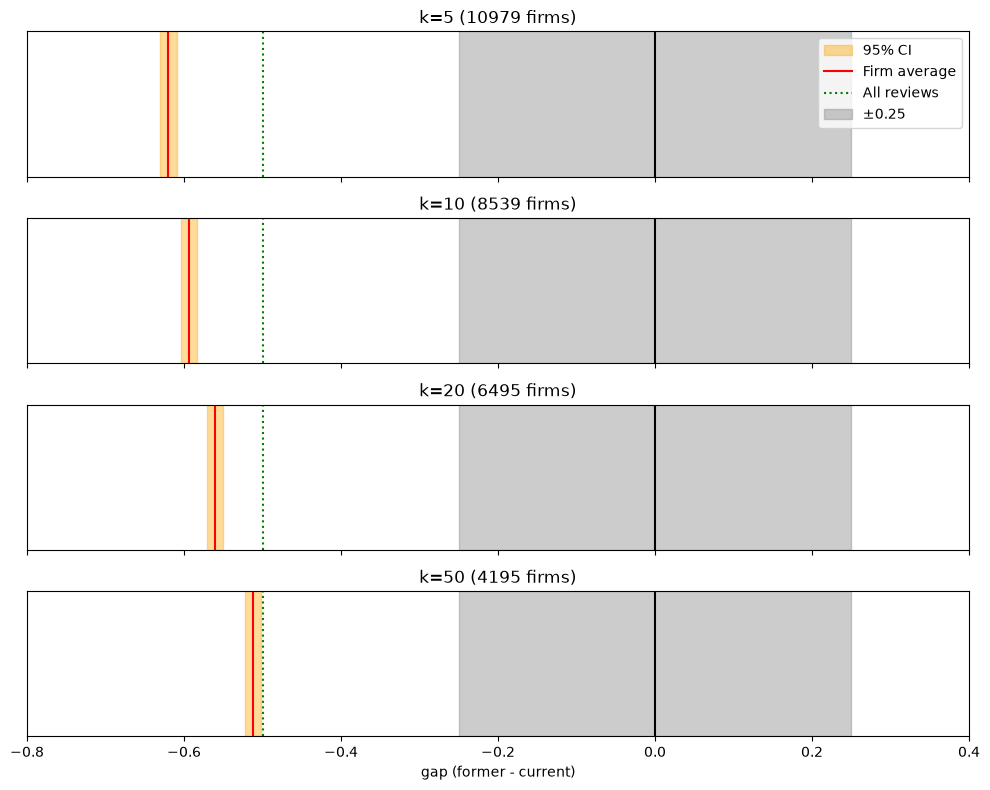

In [25]:
fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
for ax, r in zip(axes, rows):
    ax.axvspan(r["lower"], r["upper"], color="orange", alpha=0.4, label="95% CI")
    ax.axvline(r["mean"], color="red", label="Firm average")
    ax.axvline(overall_gap, color="green", linestyle=":", label="All reviews")
    ax.axvspan(-0.25, +0.25, color="gray", alpha=0.4, label="±0.25")
    ax.axvline(0, color="black")
    ax.set_title(f"k={r['k']} ({r['firms']} firms)")
    ax.set_yticks([])
axes[0].legend()
axes[-1].set_xlim(-0.8, 0.4)
axes[-1].set_xlabel("gap (former - current)")
plt.tight_layout()
plt.show()

Our decision rule is as follows:

| RQ  | Compared with                    | If different                                        | If similar                 |
| :-- | :------------------------------- | :-------------------------------------------------- | :------------------------- |
| RQ1 | Pooled gap (-0.50)               | Employer mix was distorting the pooled gap          | The pooled gap is enough   |

The result shows that there is a significant gap between former and current employees' ratings. Across the four samples (k = 5, 10, 20, 50), observed gaps are slightly lower than the pooled gap (-0.50). But the difference from the pooled gap is at most about 0.12, below the 0.25 threshold, so the pooled gap is enough. We also found that the rating gap gets narrower as the number of reviews increases.